<a href="https://colab.research.google.com/github/ValentinaEmili/Texture-synthesis/blob/main/codebook/results/img_size_512.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install lpips
!pip install import-ipynb -q

import os
from PIL import Image
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.nn.functional as F
import torch
import torch.optim as optim
from torchvision.models import vgg16
import lpips
import matplotlib.pyplot as plt
import time
import numpy as np
import math
import sys
import import_ipynb

REPO_DIR = '/content/Texture_synthesis'
os.chdir('/content')

if not os.path.exists(REPO_DIR):
  !git clone https://github.com/ValentinaEmili/Texture-synthesis.git Texture_synthesis

if REPO_DIR not in sys.path:
  sys.path.append(REPO_DIR)

In [3]:
#split = '1'
#split = '2'
split = '1_2'

batch_size = 8
#batch_size = 4

embedding_dim=128
#embedding_dim=256

num_embeddings=256
#num_embeddings=512

size, resize = 512, 560

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

perceptual_loss_fn = lpips.LPIPS(net='vgg').to(device)
perceptual_loss_fn.eval()
for p in perceptual_loss_fn.parameters():
    p.requires_grad_(False)

train_file = 'train_' + split + '.txt'
val_file = 'val_' + split + '.txt'
test_file = 'test_' + split + '.txt'

path_images = "drive/MyDrive/DeepLearning/dtd/images"
path_labels = "drive/MyDrive/DeepLearning/dtd/labels"

train_transform = transforms.Compose([
        transforms.Resize(resize),
        transforms.RandomCrop(size),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
        ])

eval_transform = transforms.Compose([
        transforms.Resize(resize),
        transforms.CenterCrop(size),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
        ])

class DTD_Dataset(Dataset):
    def __init__(self, root, file_list, transform=None, class_to_idx=None):
        self.root = root
        self.transform = transform

        with open(file_list, mode='r', encoding='utf-8') as f:
            self.files = [line.strip() for line in f if line.strip()]

        if class_to_idx is None:
          unique_classes = sorted({os.path.normpath(p).split(os.sep)[0] for p in self.files})
          self.class_to_idx = {class_name: i for i, class_name in enumerate(unique_classes)}
        else:
          self.class_to_idx = class_to_idx

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        relative_path = self.files[idx]
        image_path = os.path.join(self.root, relative_path)
        img = Image.open(image_path).convert('RGB')
        rel_norm = os.path.normpath(relative_path)
        string_label = rel_norm.split(os.sep, 1)[0]
        label = self.class_to_idx[string_label]

        if self.transform:
            img = self.transform(img)

        return img, label

train_dataset = DTD_Dataset(path_images, os.path.join(path_labels, train_file), train_transform)
class_to_idx = train_dataset.class_to_idx
val_dataset = DTD_Dataset(path_images, os.path.join(path_labels, val_file), eval_transform, class_to_idx=class_to_idx)
test_dataset = DTD_Dataset(path_images, os.path.join(path_labels, test_file), eval_transform, class_to_idx=class_to_idx)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2)

Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:06<00:00, 84.9MB/s]


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/vgg.pth


In [4]:
from Texture_synthesis.codebook.VQ_VAE import VQ_VAE
from Texture_synthesis.codebook.VQGAN import VQGAN
from Texture_synthesis.codebook.VQGAN_TT import VQGAN as VQGAN_TT

In [5]:
def visual_validation(model, val_loader, device, show_imgs=True):
  model.eval()

  all_indices = []
  visual_samples = None
  total_loss, total_percept, total_recon, total_vq = 0.0, 0.0, 0.0, 0.0

  num_embeddings = model.vq.num_embeddings
  embedding_dim = model.vq.embedding_dim
  embeddings = model.vq.embeddings.weight

  with torch.no_grad():
    for batch_idx, (data, _) in enumerate(val_loader):
      data = data.to(device)
      data_recon, vq_loss = model(data)

      visual_samples = (data.cpu(), data_recon.cpu())

      recon_loss = F.mse_loss(data_recon, data)
      percept_loss = perceptual_loss_fn(data_recon, data).mean()
      loss = percept_loss + vq_loss + recon_loss * 0.2

      total_recon += recon_loss.item()
      total_percept += percept_loss.item()
      total_vq += vq_loss.item()
      total_loss += loss.item()

      z = model.encoder(data)
      if model_type == 'vq_gan_tt': z = model.quant_conv(z)
      z_flattened = z.permute(0, 2, 3, 1).contiguous().view(-1, embedding_dim)

      distances = (torch.sum(z_flattened**2, dim=1, keepdim=True)
                    + torch.sum(embeddings**2, dim=1)
                    - 2 * torch.matmul(z_flattened, embeddings.t()))

      indices = torch.argmin(distances, dim=1)
      all_indices.append(indices.cpu())

  # percentage of used vectors
  encoding_indices = torch.cat(all_indices)
  unique_indices = torch.unique(encoding_indices)
  util_percen = len(unique_indices) / num_embeddings * 100

  # perplexity
  counts = torch.bincount(encoding_indices, minlength=num_embeddings).float()
  probs = counts / counts.sum()
  perplexity = torch.exp(-torch.sum(probs * torch.log(probs + 1e-10)))

  avg_loss = total_loss / len(val_loader)
  avg_recon = total_recon / len(val_loader)
  avg_percept = total_percept / len(val_loader)
  avg_vq = total_vq / len(val_loader)

  selection_score = avg_percept + 0.2 * avg_recon
  unique_vectors_used = (len(unique_indices) / num_embeddings) * 100

  # visual reconstruction plotting
  if (show_imgs):
    print(f"Perceptual Loss: {avg_percept:.4f}  \nReconstruction Loss: {avg_recon:.4f}  \nCodebook Loss: {avg_vq:.4f}")
    print(f"Unique Vectors Used: {unique_vectors_used:.4f}%  \nCodebook Utilization: {util_percen:.2f}%  \nCodebook Perplexity: {perplexity.item():.2f}")

    real_imgs, recon_imgs = visual_samples
    num_displayed_imgs = min(8, real_imgs.shape[0])

    fig, axes = plt.subplots(2, num_displayed_imgs, figsize=(num_displayed_imgs * 3, 6))

    for i in range(num_displayed_imgs):
      real_img = real_imgs[i].permute(1, 2, 0).numpy()
      recon_img = recon_imgs[i].permute(1, 2, 0).numpy()

      real_plot = ((real_img + 1) / 2).clip(0, 1)
      recon_plot = ((recon_img + 1) / 2).clip(0, 1)

      axes[0, i].imshow(real_plot)
      axes[0, i].set_title(f"original {i+1}")
      axes[0, i].axis('off')

      axes[1, i].imshow(recon_plot)
      axes[1, i].set_title(f"reconstructed {i+1}")
      axes[1, i].axis('off')

    plt.show()

  else:
    print(f"Val Loss: {avg_loss:.4f}  | Perceptual Loss: {avg_percept:.4f}  | Reconstruction Loss: {avg_recon:.4f}  | Codebook Loss: {avg_vq:.4f}")
    print(f"Unique Vectors Used: {unique_vectors_used:.4f}%  | Codebook Utilization: {util_percen:.2f}%  | Codebook Perplexity: {perplexity.item():.2f}")

  return selection_score, unique_vectors_used, perplexity.item()

## ***IMAGES SIZE=512***

### 512-D embeddings

#### Split 1

##### embedding_dim=128

VQ-VAE
Perceptual Loss: 0.5267  
Reconstruction Loss: 0.0773  
Codebook Loss: 0.2666
Unique Vectors Used: 48.4375%  
Codebook Utilization: 48.44%  
Codebook Perplexity: 39.06


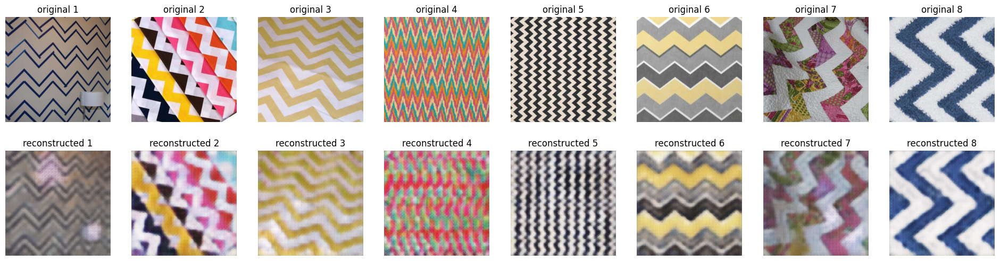

VQGAN
Perceptual Loss: 0.5565  
Reconstruction Loss: 0.0899  
Codebook Loss: 0.2242
Unique Vectors Used: 15.8203%  
Codebook Utilization: 15.82%  
Codebook Perplexity: 49.29


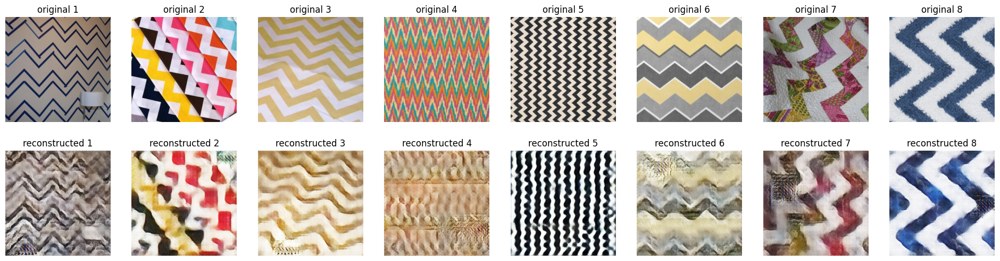

In [ ]:
print("VQ-VAE")

gen_save_path = f'/content/drive/MyDrive/DeepLearning/dtd/new_checkpoints/vq_vae/best_{split}_{embedding_dim}_{num_embeddings}.pth'
checkpoint = torch.load(gen_save_path, weights_only=True)
generator = VQ_VAE(hidden_dim=128, embedding_dim=embedding_dim, num_embeddings=num_embeddings).to(device)
generator.load_state_dict(checkpoint['model_state_dict'])
_, _, _ = visual_validation(generator, val_loader, device)

print("VQGAN")

gen_save_path = f'/content/drive/MyDrive/DeepLearning/dtd/new_checkpoints/vq_gan/gen_best_{split}_{embedding_dim}_{num_embeddings}.pth'
checkpoint = torch.load(gen_save_path, weights_only=True)
generator = VQGAN(hidden_dim=128, embedding_dim=embedding_dim, num_embeddings=num_embeddings).to(device)
generator.load_state_dict(checkpoint['model_state_dict'])
_, _, _ = visual_validation(generator, val_loader, device)

##### embedding_dim=256

VQ-VAE
Perceptual Loss: 0.5271  
Reconstruction Loss: 0.0905  
Codebook Loss: 0.1327
Unique Vectors Used: 30.0781%  
Codebook Utilization: 30.08%  
Codebook Perplexity: 26.27


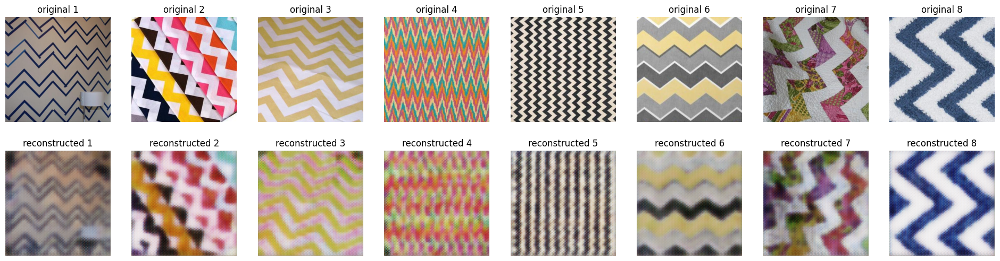

VQGAN
Perceptual Loss: 0.5578  
Reconstruction Loss: 0.0941  
Codebook Loss: 0.1984
Unique Vectors Used: 13.8672%  
Codebook Utilization: 13.87%  
Codebook Perplexity: 46.47


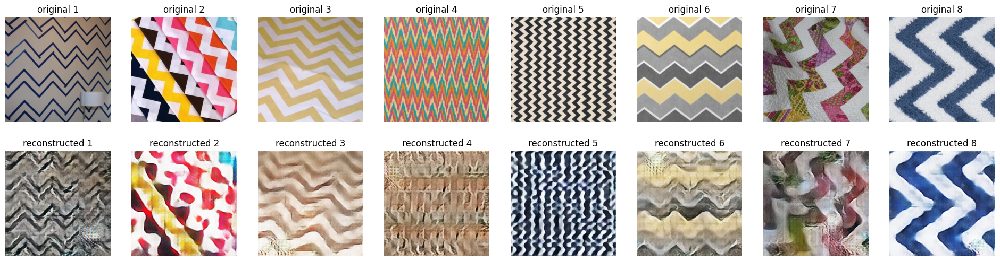

In [ ]:
print("VQ-VAE")

gen_save_path = f'/content/drive/MyDrive/DeepLearning/dtd/new_checkpoints/vq_vae/best_{split}_{embedding_dim}_{num_embeddings}.pth'
checkpoint = torch.load(gen_save_path, weights_only=True)
generator = VQ_VAE(hidden_dim=128, embedding_dim=embedding_dim, num_embeddings=num_embeddings).to(device)
generator.load_state_dict(checkpoint['model_state_dict'])
_, _, _ = visual_validation(generator, val_loader, device)

print("VQGAN")

gen_save_path = f'/content/drive/MyDrive/DeepLearning/dtd/new_checkpoints/vq_gan/gen_best_{split}_{embedding_dim}_{num_embeddings}.pth'
checkpoint = torch.load(gen_save_path, weights_only=True)
generator = VQGAN(hidden_dim=128, embedding_dim=embedding_dim, num_embeddings=num_embeddings).to(device)
generator.load_state_dict(checkpoint['model_state_dict'])
_, _, _ = visual_validation(generator, val_loader, device)

#### Split 2

##### embedding_dim=128

VQ-VAE
Perceptual Loss: 0.5222  
Reconstruction Loss: 0.0723  
Codebook Loss: 0.2735
Unique Vectors Used: 38.2812%  
Codebook Utilization: 38.28%  
Codebook Perplexity: 45.14


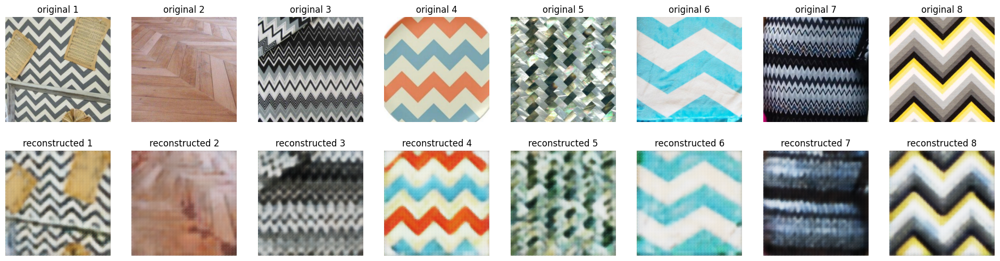

VQGAN
Perceptual Loss: 0.5492  
Reconstruction Loss: 0.0870  
Codebook Loss: 0.1778
Unique Vectors Used: 18.5547%  
Codebook Utilization: 18.55%  
Codebook Perplexity: 55.48


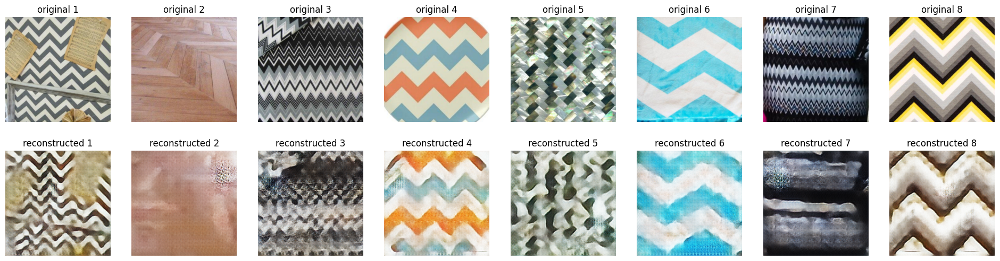

In [ ]:
print("VQ-VAE")

gen_save_path = f'/content/drive/MyDrive/DeepLearning/dtd/new_checkpoints/vq_vae/best_{split}_{embedding_dim}_{num_embeddings}.pth'
checkpoint = torch.load(gen_save_path, weights_only=True)
generator = VQ_VAE(hidden_dim=128, embedding_dim=embedding_dim, num_embeddings=num_embeddings).to(device)
generator.load_state_dict(checkpoint['model_state_dict'])
_, _, _ = visual_validation(generator, val_loader, device)

print("VQGAN")

gen_save_path = f'/content/drive/MyDrive/DeepLearning/dtd/new_checkpoints/vq_gan/gen_best_{split}_{embedding_dim}_{num_embeddings}.pth'
checkpoint = torch.load(gen_save_path, weights_only=True)
generator = VQGAN(hidden_dim=128, embedding_dim=embedding_dim, num_embeddings=num_embeddings).to(device)
generator.load_state_dict(checkpoint['model_state_dict'])
_, _, _ = visual_validation(generator, val_loader, device)

##### embedding_dim=256

VQ-VAE
Perceptual Loss: 0.5361  
Reconstruction Loss: 0.0979  
Codebook Loss: 0.1607
Unique Vectors Used: 16.7969%  
Codebook Utilization: 16.80%  
Codebook Perplexity: 24.55


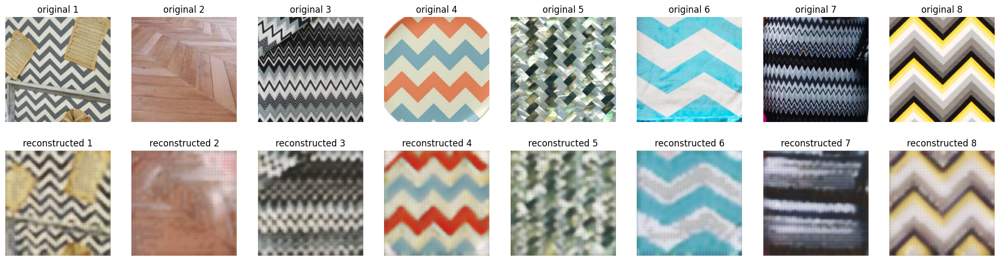

VQGAN
Perceptual Loss: 0.5535  
Reconstruction Loss: 0.0939  
Codebook Loss: 0.2227
Unique Vectors Used: 13.8672%  
Codebook Utilization: 13.87%  
Codebook Perplexity: 50.53


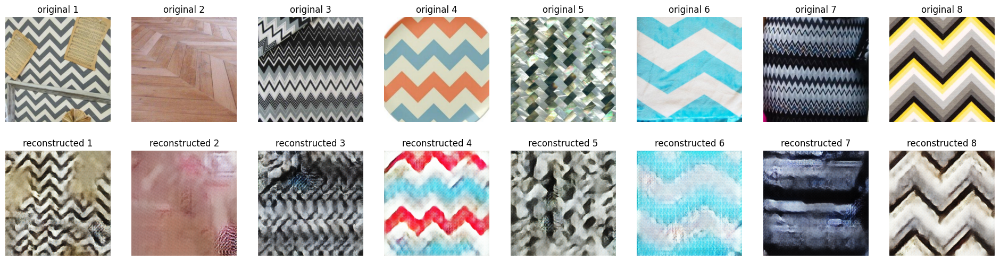

In [ ]:
print("VQ-VAE")

gen_save_path = f'/content/drive/MyDrive/DeepLearning/dtd/new_checkpoints/vq_vae/best_{split}_{embedding_dim}_{num_embeddings}.pth'
checkpoint = torch.load(gen_save_path, weights_only=True)
generator = VQ_VAE(hidden_dim=128, embedding_dim=embedding_dim, num_embeddings=num_embeddings).to(device)
generator.load_state_dict(checkpoint['model_state_dict'])
model_type = 'vq_vae'
_, _, _ = visual_validation(generator, val_loader, device)

print("VQGAN")

gen_save_path = f'/content/drive/MyDrive/DeepLearning/dtd/new_checkpoints/vq_gan/gen_best_{split}_{embedding_dim}_{num_embeddings}.pth'
checkpoint = torch.load(gen_save_path, weights_only=True)
generator = VQGAN(hidden_dim=128, embedding_dim=embedding_dim, num_embeddings=num_embeddings).to(device)
generator.load_state_dict(checkpoint['model_state_dict'])
model_type = 'vq_gan'
_, _, _ = visual_validation(generator, val_loader, device)

#### Split 1 and 2

##### embedding_dim=128

VQ-VAE
Perceptual Loss: 0.4648  
Reconstruction Loss: 0.0576  
Codebook Loss: 0.4578
Unique Vectors Used: 47.4609%  
Codebook Utilization: 47.46%  
Codebook Perplexity: 67.11


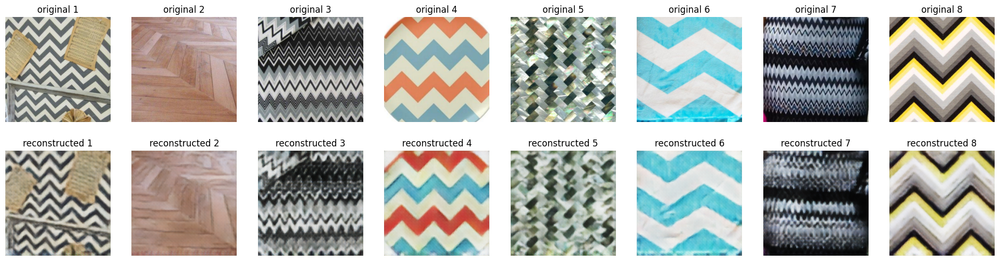

VQGAN
Perceptual Loss: 0.5122  
Reconstruction Loss: 0.0679  
Codebook Loss: 0.1501
Unique Vectors Used: 23.4375%  
Codebook Utilization: 23.44%  
Codebook Perplexity: 87.44


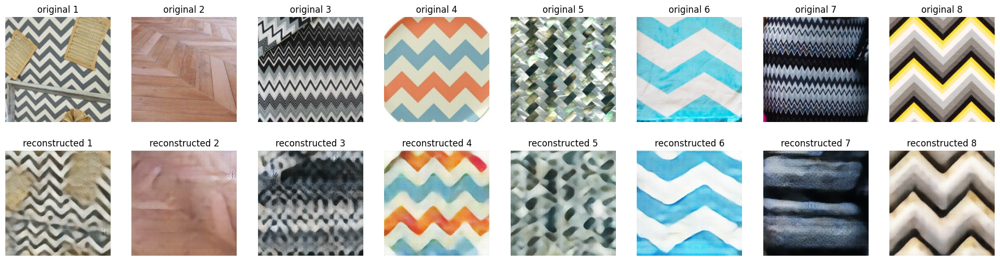

In [ ]:
print("VQ-VAE")

gen_save_path = f'/content/drive/MyDrive/DeepLearning/dtd/new_checkpoints/vq_vae/best_{split}_{embedding_dim}_{num_embeddings}.pth'
checkpoint = torch.load(gen_save_path, weights_only=True)
generator = VQ_VAE(hidden_dim=128, embedding_dim=embedding_dim, num_embeddings=num_embeddings).to(device)
generator.load_state_dict(checkpoint['model_state_dict'])
model_type = 'vq_vae'
_, _, _ = visual_validation(generator, val_loader, device)

print("VQGAN")

gen_save_path = f'/content/drive/MyDrive/DeepLearning/dtd/new_checkpoints/vq_gan/gen_best_{split}_{embedding_dim}_{num_embeddings}.pth'
checkpoint = torch.load(gen_save_path, weights_only=True)
generator = VQGAN(hidden_dim=128, embedding_dim=embedding_dim, num_embeddings=num_embeddings).to(device)
generator.load_state_dict(checkpoint['model_state_dict'])
model_type = 'vq_gan'
_, _, _ = visual_validation(generator, val_loader, device)

##### embedding_dim=256

VQ-VAE
Perceptual Loss: 0.4655  
Reconstruction Loss: 0.0604  
Codebook Loss: 0.3713
Unique Vectors Used: 21.2891%  
Codebook Utilization: 21.29%  
Codebook Perplexity: 40.63


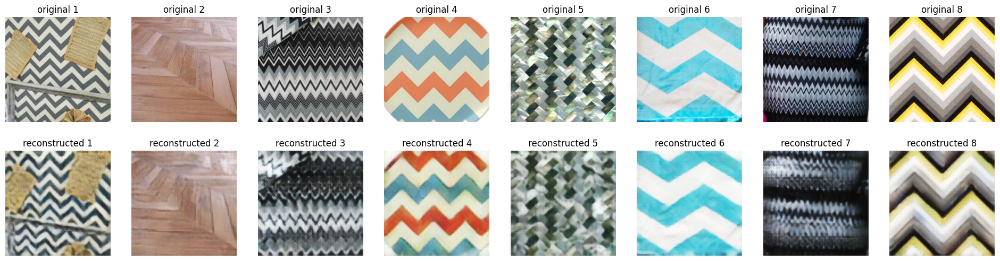

VQGAN
Perceptual Loss: 0.5293  
Reconstruction Loss: 0.0760  
Codebook Loss: 0.1941
Unique Vectors Used: 22.2656%  
Codebook Utilization: 22.27%  
Codebook Perplexity: 79.87


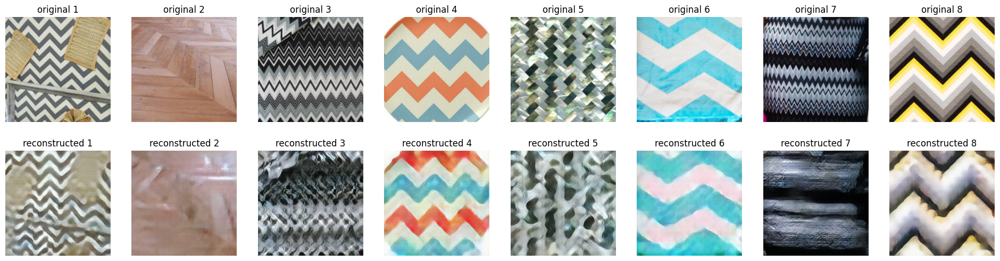

In [ ]:
print("VQ-VAE")

gen_save_path = f'/content/drive/MyDrive/DeepLearning/dtd/new_checkpoints/vq_vae/best_{split}_{embedding_dim}_{num_embeddings}.pth'
checkpoint = torch.load(gen_save_path, weights_only=True)
generator = VQ_VAE(hidden_dim=128, embedding_dim=embedding_dim, num_embeddings=num_embeddings).to(device)
generator.load_state_dict(checkpoint['model_state_dict'])
model_type = 'vq_vae'
_, _, _ = visual_validation(generator, val_loader, device)

print("VQGAN")

gen_save_path = f'/content/drive/MyDrive/DeepLearning/dtd/new_checkpoints/vq_gan/gen_best_{split}_{embedding_dim}_{num_embeddings}.pth'
checkpoint = torch.load(gen_save_path, weights_only=True)
generator = VQGAN(hidden_dim=128, embedding_dim=embedding_dim, num_embeddings=num_embeddings).to(device)
generator.load_state_dict(checkpoint['model_state_dict'])
model_type = 'vq_gan'
_, _, _ = visual_validation(generator, val_loader, device)

### 256-D embeddings    (embedding_dim=128)

#### Split 1

VQ-VAE
Perceptual Loss: 0.5197  
Reconstruction Loss: 0.0785  
Codebook Loss: 0.3093
Unique Vectors Used: 58.2031%  
Codebook Utilization: 58.20%  
Codebook Perplexity: 32.90


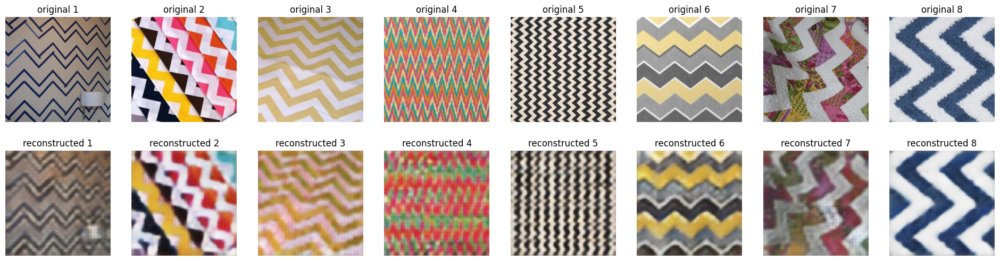

VQGAN
Perceptual Loss: 0.5607  
Reconstruction Loss: 0.0938  
Codebook Loss: 0.1954
Unique Vectors Used: 36.3281%  
Codebook Utilization: 36.33%  
Codebook Perplexity: 52.75


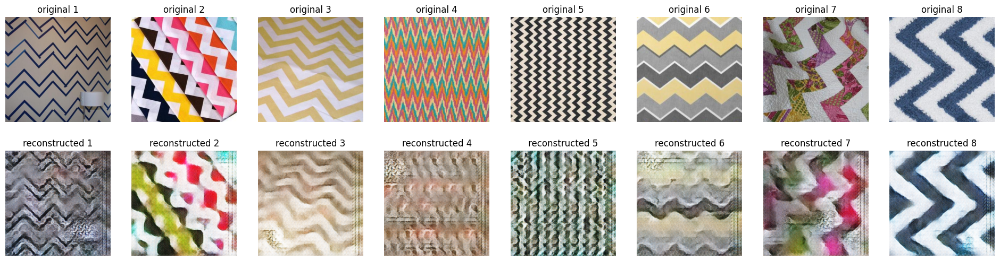

In [ ]:
print("VQ-VAE")

gen_save_path = f'/content/drive/MyDrive/DeepLearning/dtd/new_checkpoints/vq_vae/best_{split}_{embedding_dim}_{num_embeddings}.pth'
checkpoint = torch.load(gen_save_path, weights_only=True)
generator = VQ_VAE(hidden_dim=128, embedding_dim=embedding_dim, num_embeddings=num_embeddings).to(device)
generator.load_state_dict(checkpoint['model_state_dict'])
model_type = 'vq_vae'
_, _, _ = visual_validation(generator, val_loader, device)

print("VQGAN")

gen_save_path = f'/content/drive/MyDrive/DeepLearning/dtd/new_checkpoints/vq_gan/gen_best_{split}_{embedding_dim}_{num_embeddings}.pth'
checkpoint = torch.load(gen_save_path, weights_only=True)
generator = VQGAN(hidden_dim=128, embedding_dim=embedding_dim, num_embeddings=num_embeddings).to(device)
generator.load_state_dict(checkpoint['model_state_dict'])
model_type = 'vq_gan'
_, _, _ = visual_validation(generator, val_loader, device)

#### Split 2

VQ-VAE
Perceptual Loss: 0.5355  
Reconstruction Loss: 0.0852  
Codebook Loss: 0.1387
Unique Vectors Used: 55.0781%  
Codebook Utilization: 55.08%  
Codebook Perplexity: 28.88


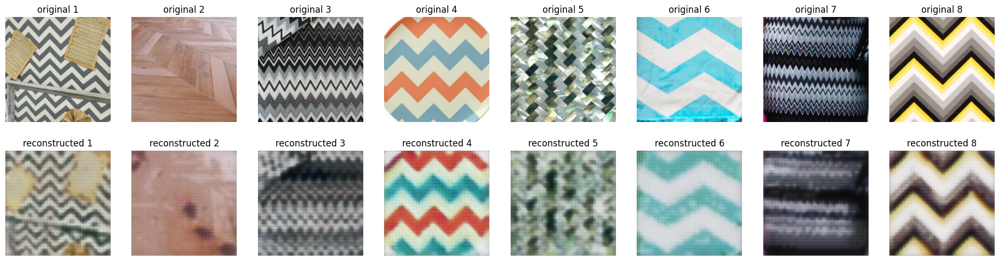

VQGAN
Perceptual Loss: 0.5736  
Reconstruction Loss: 0.1076  
Codebook Loss: 0.1374
Unique Vectors Used: 40.2344%  
Codebook Utilization: 40.23%  
Codebook Perplexity: 51.65


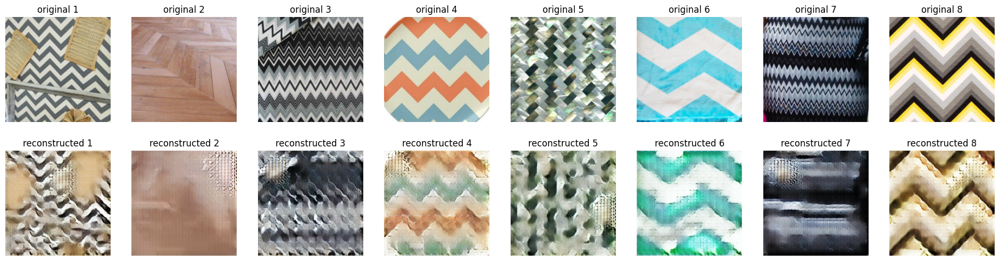

In [ ]:
print("VQ-VAE")

gen_save_path = f'/content/drive/MyDrive/DeepLearning/dtd/new_checkpoints/vq_vae/best_{split}_{embedding_dim}_{num_embeddings}.pth'
checkpoint = torch.load(gen_save_path, weights_only=True)
generator = VQ_VAE(hidden_dim=128, embedding_dim=embedding_dim, num_embeddings=num_embeddings).to(device)
generator.load_state_dict(checkpoint['model_state_dict'])
model_type = 'vq_vae'
_, _, _ = visual_validation(generator, val_loader, device)

print("VQGAN")

gen_save_path = f'/content/drive/MyDrive/DeepLearning/dtd/new_checkpoints/vq_gan/gen_best_{split}_{embedding_dim}_{num_embeddings}.pth'
checkpoint = torch.load(gen_save_path, weights_only=True)
generator = VQGAN(hidden_dim=128, embedding_dim=embedding_dim, num_embeddings=num_embeddings).to(device)
generator.load_state_dict(checkpoint['model_state_dict'])
model_type = 'vq_gan'
_, _, _ = visual_validation(generator, val_loader, device)

#### Split 1 and 2

VQ-VAE
Perceptual Loss: 0.4643  
Reconstruction Loss: 0.0605  
Codebook Loss: 0.4785
Unique Vectors Used: 76.9531%  
Codebook Utilization: 76.95%  
Codebook Perplexity: 59.91


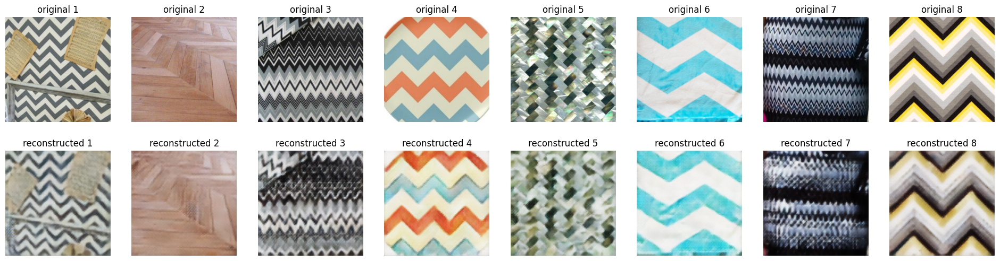

VQGAN
Perceptual Loss: 0.5195  
Reconstruction Loss: 0.0733  
Codebook Loss: 0.1474
Unique Vectors Used: 48.4375%  
Codebook Utilization: 48.44%  
Codebook Perplexity: 84.81


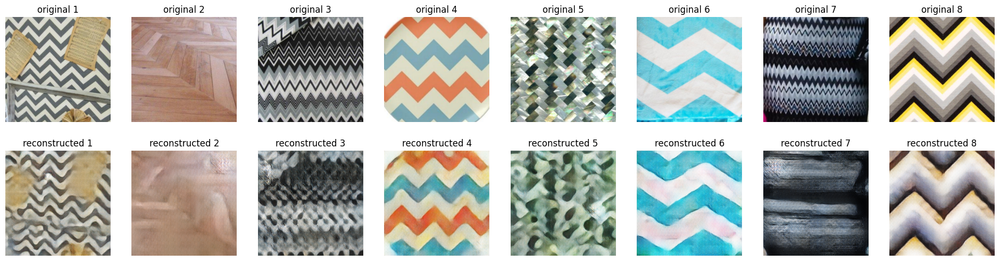

In [6]:
print("VQ-VAE")

gen_save_path = f'/content/drive/MyDrive/DeepLearning/dtd/new_checkpoints/vq_vae/best_{split}_{embedding_dim}_{num_embeddings}.pth'
checkpoint = torch.load(gen_save_path, weights_only=True)
generator = VQ_VAE(hidden_dim=128, embedding_dim=embedding_dim, num_embeddings=num_embeddings).to(device)
generator.load_state_dict(checkpoint['model_state_dict'])
model_type = 'vq_vae'
_, _, _ = visual_validation(generator, val_loader, device)

print("VQGAN")

gen_save_path = f'/content/drive/MyDrive/DeepLearning/dtd/new_checkpoints/vq_gan/gen_best_{split}_{embedding_dim}_{num_embeddings}.pth'
checkpoint = torch.load(gen_save_path, weights_only=True)
generator = VQGAN(hidden_dim=128, embedding_dim=embedding_dim, num_embeddings=num_embeddings).to(device)
generator.load_state_dict(checkpoint['model_state_dict'])
model_type = 'vq_gan'
_, _, _ = visual_validation(generator, val_loader, device)